In [1]:
import os
import sys

def find_order_analyzer_parent(start=None):
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, "features")) and os.path.isdir(os.path.join(current, "OCTA_toolbox-master")):
            return os.path.abspath(os.path.join(current, os.pardir))
        if os.path.isdir(os.path.join(current, "order_analyzer")) and os.path.isdir(os.path.join(current, "order_analyzer", "features")):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise RuntimeError(f"Cannot find order_analyzer parent from cwd={os.getcwd()}")
        current = parent

project_parent = find_order_analyzer_parent()
if project_parent not in sys.path:
    sys.path.insert(0, project_parent)

from order_analyzer import OrderAnalyzer, TableGrid, TableTemplate
from order_analyzer.features.affordance import resolution_comparison_svg, scene_grid_overlay_svg
from IPython.display import SVG, display

print("added path:", project_parent)
print("cwd:", os.getcwd())


added path: D:\PROJECTS\understandOtherPackage
cwd: D:\PROJECTS\understandOtherPackage\order_analyzer\test


In [2]:
LAYOUT_SIZE = (360, 360)
RESOLUTION = 20

standard_table = TableTemplate(
    size=(64, 44),
    type_id="table.default",
    affordance={"usable_edges": ("right",), "edge_depth": {"right": 18}},
    aisle={"min_width": 80},
)

ideal_grid = TableGrid(3, 3, fill=standard_table)
grid = TableGrid(3, 3, fill=standard_table)

# 1-based 1,2 means Python [0][1]. This instance is pushed to the right edge of its cell.
grid.place(0, 1, align="right")
# 1-based 3,3 means Python [2][2]. Rotate it to smoke-check orientation handling.
grid.place(2, 2, orientation=45)
# RoadNetwork gives every semantic grid line a Road intent. Road-road overlaps union automatically.
# RoadBand / ClearanceBand are continuous geometry; sampled cells below are only debug explanations.
grid.enable_road_network(width=12, min_clearance=12)
grid.road(axis="vertical", index=1, width=16, min_clearance=16)
grid.road(axis="horizontal", index=2, enabled=False)

ideal_layout = ideal_grid.to_layout()
actual_layout = grid.to_layout()
ideal = ideal_grid.to_matrix()
actual = grid.to_matrix()


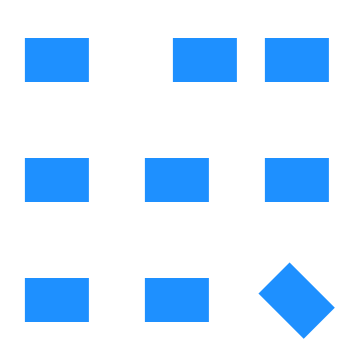

In [3]:
analyzer = OrderAnalyzer(
    actual_matrix=actual_layout,
    ideal_matrix=ideal_layout,
    layout_size=LAYOUT_SIZE,
    fit_to_layout=True,
)
analyzer._prepare()
analyzer._stim.Show()


In [4]:
report = OrderAnalyzer(
    actual_matrix=actual_layout,
    ideal_matrix=ideal_layout,
    layout_size=LAYOUT_SIZE,
    fit_to_layout=True,
).report(
    features=("positions", "orientations"),
    include_affordance=True,
    affordance_options={"width": LAYOUT_SIZE[0], "height": LAYOUT_SIZE[1], "resolution": RESOLUTION},
)


In [5]:
# continuous_conflicts are the geometry-based conflict source of truth.
# debug.* cell counts are sampled explanations and may change with resolution.
print("order:", report["order"])
print("scores:", report["scores"])
print("deviance_by_feature:", report["deviance_by_feature"])
print("deviance_cells:", report["deviance_cells"])
print("affordance.score:", report["affordance"]["score"])
print("affordance.violations:", report["affordance"]["violations"])
print("aisle.score:", report["aisle"]["score"])
print("aisle.bottlenecks:", report["aisle"]["bottlenecks"])
print("aisle.objects.t12:", report["aisle"]["objects"]["t12"])
print("aisle.roads:", report["aisle"].get("roads"))
print("aisle.clearance:", report["aisle"].get("clearance"))
print("debug.road cells:", sum(sum(row) for row in report["aisle"]["debug"]["road"]))
print("debug.clearance cells:", sum(sum(row) for row in report["aisle"]["debug"]["clearance"]))
print("debug.clearance_conflict cells:", sum(sum(row) for row in report["aisle"]["debug"]["clearance_conflict"]))
print("debug.aisle cells:", sum(sum(row) for row in report["aisle"]["debug"]["aisle"]))
print("debug.aisle_conflict cells:", sum(sum(row) for row in report["aisle"]["debug"]["aisle_conflict"]))

print("affordance.continuous_conflicts:", report["affordance"]["debug"].get("continuous_conflicts", []))
print("aisle.continuous_conflicts:", report["aisle"]["debug"].get("continuous_conflicts", []))


order: 0.7778
scores: {'base_order': 0.7778, 'intra': 0.9853, 'inter': 1.0, 'rel': None, 'total': 0.9042}
deviance_by_feature: {'positions': {'count': 1, 'ratio': 0.1111}, 'orientations': {'count': 1, 'ratio': 0.1111}}
deviance_cells: [{'row': 0, 'col': 1}, {'row': 2, 'col': 2}]
affordance.score: 1.0
affordance.violations: []
aisle.score: 0.7857
aisle.bottlenecks: [{'type': 'clearance_blocked', 'severity': 'hard', 'object_ids': ['road.vertical.2.clearance', 't12'], 'source_id': 'road.vertical.2.clearance', 'target_id': 't12', 'suggestion_hint': 'increase_clearance_band'}, {'type': 'road_affordance_conflict', 'severity': 'soft', 'object_ids': ['road.vertical.2.clearance', 't12'], 'source_id': 'road.vertical.2.clearance', 'target_id': 't12.right.affordance', 'suggestion_hint': 'separate_road_from_affordance'}]
aisle.objects.t12: {'aisle_cells': 0, 'blocked_aisle_cells': 0, 'affordance_conflict_cells': 0}
aisle.roads: {'road.vertical.0': {'road_cells': 18}, 'road.vertical.1': {'road_cells

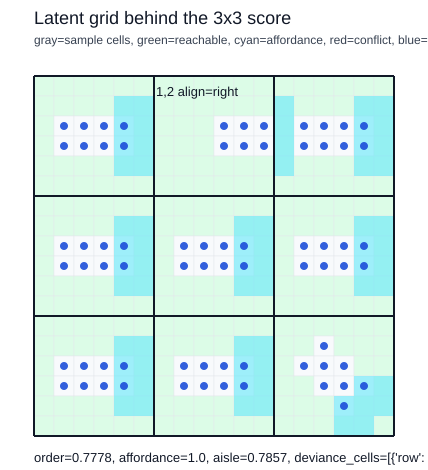

In [6]:
from IPython.display import SVG, display

def latent_grid_svg(report, cell_size=120, sample=20):
    occupied = report["affordance"]["debug"]["occupied"]
    affordance = report["affordance"]["debug"]["affordance"]
    conflict = report["affordance"]["debug"]["conflict"]
    reachable = report["aisle"]["debug"]["reachable"]
    width = LAYOUT_SIZE[0]
    height = LAYOUT_SIZE[1]
    margin = 34
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width + margin * 2}" height="{height + margin * 2 + 42}" viewBox="0 0 {width + margin * 2} {height + margin * 2 + 42}">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="{margin}" y="24" font-size="18" font-family="Arial" fill="#111827">Latent grid behind the 3x3 score</text>',
        f'<text x="{margin}" y="44" font-size="12" font-family="Arial" fill="#374151">gray=sample cells, green=reachable, cyan=affordance, red=conflict, blue=occupied; thick lines=3x3 semantic grid</text>',
    ]
    ox = margin
    oy = margin + 42
    for r, row in enumerate(reachable):
        for c, value in enumerate(row):
            x = ox + c * sample
            y = oy + r * sample
            fill = "#dcfce7" if value else "#f8fafc"
            parts.append(f'<rect x="{x}" y="{y}" width="{sample}" height="{sample}" fill="{fill}" stroke="#e5e7eb" stroke-width="0.5"/>')
    for r, row in enumerate(affordance):
        for c, value in enumerate(row):
            if value:
                parts.append(f'<rect x="{ox + c * sample}" y="{oy + r * sample}" width="{sample}" height="{sample}" fill="#67e8f9" opacity="0.62"/>')
    for r, row in enumerate(conflict):
        for c, value in enumerate(row):
            if value:
                parts.append(f'<rect x="{ox + c * sample}" y="{oy + r * sample}" width="{sample}" height="{sample}" fill="#ef4444" opacity="0.85"/>')
    for r, row in enumerate(occupied):
        for c, value in enumerate(row):
            if value:
                parts.append(f'<circle cx="{ox + c * sample + sample / 2}" cy="{oy + r * sample + sample / 2}" r="4" fill="#1d4ed8" opacity="0.9"/>')
    for i in range(4):
        x = ox + i * cell_size
        y = oy + i * cell_size
        parts.append(f'<line x1="{x}" y1="{oy}" x2="{x}" y2="{oy + height}" stroke="#111827" stroke-width="2"/>')
        parts.append(f'<line x1="{ox}" y1="{y}" x2="{ox + width}" y2="{y}" stroke="#111827" stroke-width="2"/>')
    parts.append(f'<text x="{ox + 122}" y="{oy + 20}" font-size="13" font-family="Arial" fill="#111827">1,2 align=right</text>')
    parts.append(f'<text x="{ox}" y="{oy + height + 26}" font-size="13" font-family="Arial" fill="#111827">order={report["order"]}, affordance={report["affordance"]["score"]}, aisle={report["aisle"]["score"]}, deviance_cells={report["deviance_cells"]}</text>')
    parts.append('</svg>')
    return SVG(''.join(parts))

display(latent_grid_svg(report))


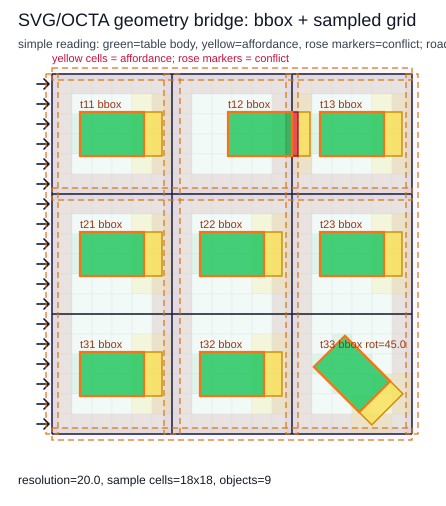

In [7]:
# SceneModel is the continuous geometry bridge between OCTA/SVG and sampled evaluation grid.
# Reading guide: red=continuous overlap, pale yellow=sampled affordance, pale green=reachable, arrows=BFS entries.
scene = analyzer._build_scene_model()
overlay_svg = scene_grid_overlay_svg(
    scene=scene,
    report=report,
    layout_size=LAYOUT_SIZE,
    resolution=RESOLUTION,
    title="SVG/OCTA geometry bridge: bbox + sampled grid",
)
display(SVG(overlay_svg))


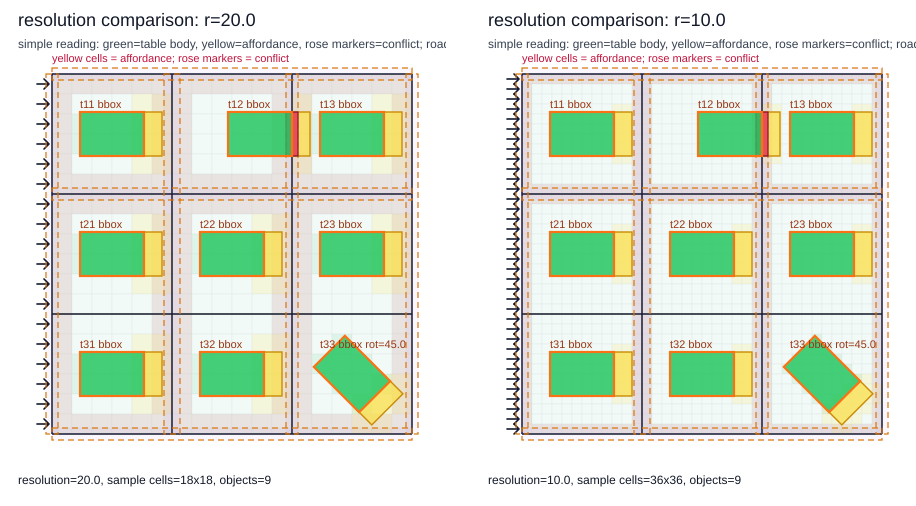

continuous conflict count is stable: 2 2
sampled clearance_conflict cells may change: 8 12


In [8]:
# resolution comparison: same continuous RoadNetwork geometry, denser sampled cells.
# Conflict existence should stay stable; only sampled explanation density should change.
fine_resolution = 10
fine_report = OrderAnalyzer(
    actual_matrix=actual_layout,
    ideal_matrix=ideal_layout,
    layout_size=LAYOUT_SIZE,
    fit_to_layout=True,
).report(
    features=("positions", "orientations"),
    include_affordance=True,
    affordance_options={"width": LAYOUT_SIZE[0], "height": LAYOUT_SIZE[1], "resolution": fine_resolution},
)
display(SVG(resolution_comparison_svg(
    scene=scene,
    report_a=report,
    report_b=fine_report,
    layout_size=LAYOUT_SIZE,
    resolution_a=RESOLUTION,
    resolution_b=fine_resolution,
)))

print("continuous conflict count is stable:", len(report["aisle"]["debug"].get("continuous_conflicts", [])), len(fine_report["aisle"]["debug"].get("continuous_conflicts", [])))
print("sampled clearance_conflict cells may change:", sum(sum(row) for row in report["aisle"]["debug"]["clearance_conflict"]), sum(sum(row) for row in fine_report["aisle"]["debug"]["clearance_conflict"]))
